# Detecção de Anomalias em Transações de Cartão de Crédito

Projeto do bootcamp **Bradesco - Agentes de IA do Zero a Prática** (DIO).

Objetivo: treinar modelos que identifiquem transações fraudulentas em uma base **muito desbalanceada**
(cerca de 0,17% de fraudes) e explicar o que levou o modelo a marcar uma transação como fraude.

Roteiro: **Explorar → Preparar → Treinar → Avaliar → Explicar**.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score, RocCurveDisplay,
                             PrecisionRecallDisplay, precision_recall_curve)
from xgboost import XGBClassifier
import shap

RANDOM_STATE = 42
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

## 1. Explorar

O dataset é carregado direto pelo link (não fica no repositório).

In [2]:
URL = "https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv"
df = pd.read_csv(URL)
print(df.shape)
df.head()

(284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0000,-1.3598,-0.0728,2.5363,1.3782,-0.3383,0.4624,0.2396,0.0987,0.3638,...,-0.0183,0.2778,-0.1105,0.0669,0.1285,-0.1891,0.1336,-0.0211,149.6200,0
1,0.0000,1.1919,0.2662,0.1665,0.4482,0.0600,-0.0824,-0.0788,0.0851,-0.2554,...,-0.2258,-0.6387,0.1013,-0.3398,0.1672,0.1259,-0.0090,0.0147,2.6900,0
2,1.0000,-1.3584,-1.3402,1.7732,0.3798,-0.5032,1.8005,0.7915,0.2477,-1.5147,...,0.2480,0.7717,0.9094,-0.6893,-0.3276,-0.1391,-0.0554,-0.0598,378.6600,0
3,1.0000,-0.9663,-0.1852,1.7930,-0.8633,-0.0103,1.2472,0.2376,0.3774,-1.3870,...,-0.1083,0.0053,-0.1903,-1.1756,0.6474,-0.2219,0.0627,0.0615,123.5000,0
4,2.0000,-1.1582,0.8777,1.5487,0.4030,-0.4072,0.0959,0.5929,-0.2705,0.8177,...,-0.0094,0.7983,-0.1375,0.1413,-0.2060,0.5023,0.2194,0.2152,69.9900,0


In [3]:
print(df.isna().sum().sum(), "valores ausentes")
contagem = df["Class"].value_counts()
proporcao = df["Class"].value_counts(normalize=True) * 100
pd.DataFrame({"transações": contagem, "%": proporcao}).rename(index={0: "normal", 1: "fraude"})

0 valores ausentes


,transações,%
Class,,
normal,284315,99.8273
fraude,492,0.1727


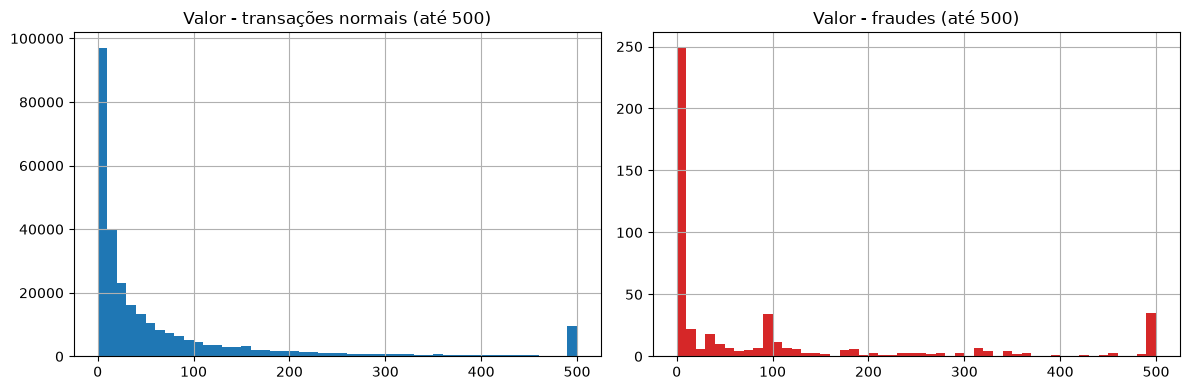

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,"284,315.0000",88.2910,250.1051,0.0000,5.6500,22.0000,77.0500,"25,691.1600"
1,492.0000,122.2113,256.6833,0.0000,1.0000,9.2500,105.8900,"2,125.8700"


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df[df.Class == 0]["Amount"].clip(upper=500).hist(bins=50, ax=axes[0], color="tab:blue")
axes[0].set_title("Valor - transações normais (até 500)")
df[df.Class == 1]["Amount"].clip(upper=500).hist(bins=50, ax=axes[1], color="tab:red")
axes[1].set_title("Valor - fraudes (até 500)")
plt.tight_layout(); plt.show()

df.groupby("Class")["Amount"].describe()

**Leitura:** um modelo que responde "não é fraude" para tudo teria ~99,83% de acurácia e não pegaria nenhuma fraude.
Por isso a avaliação usa **recall, precisão e F1 da classe fraude**, além da área sob a curva de precisão e recall (AUPRC).

## 2. Preparar

In [5]:
dados = df.copy()
dados["log_amount"] = np.log1p(dados["Amount"])          # reduz a assimetria do valor
dados["hora"] = (dados["Time"] // 3600) % 24              # hora aproximada do dia
dados = dados.drop(columns=["Amount", "Time"])

X = dados.drop(columns="Class")
y = dados["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)

scaler = StandardScaler()
X_train_s = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns, index=X_train.index)
X_test_s = pd.DataFrame(scaler.transform(X_test), columns=X.columns, index=X_test.index)

print("fraudes no treino: %.4f%% | no teste: %.4f%%" % (y_train.mean() * 100, y_test.mean() * 100))

fraudes no treino: 0.1727% | no teste: 0.1727%


## 3. Treinar

Baseline com regressão logística e comparação com Random Forest e XGBoost, todos com peso para a classe minoritária.

In [6]:
peso = (y_train == 0).sum() / (y_train == 1).sum()

modelos = {
    "Regressão Logística": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=12, min_samples_leaf=2,
                                            class_weight="balanced_subsample", n_jobs=-1,
                                            random_state=RANDOM_STATE),
    "XGBoost": XGBClassifier(n_estimators=400, max_depth=5, learning_rate=0.05, subsample=0.9,
                             colsample_bytree=0.8, scale_pos_weight=peso, eval_metric="aucpr",
                             n_jobs=-1, random_state=RANDOM_STATE),
}

probas = {}
for nome, modelo in modelos.items():
    modelo.fit(X_train_s, y_train)
    probas[nome] = modelo.predict_proba(X_test_s)[:, 1]
    print(nome, "treinado")

Regressão Logística treinado


Random Forest treinado


XGBoost treinado


### Bônus: undersampling × oversampling (com a regressão logística)

In [7]:
rng = np.random.default_rng(RANDOM_STATE)
idx_f = y_train[y_train == 1].index
idx_n = y_train[y_train == 0].index

# undersampling: reduz as normais para 5x o número de fraudes
idx_under = np.concatenate([idx_f, rng.choice(idx_n, size=len(idx_f) * 5, replace=False)])
# oversampling: replica fraudes até 10% do tamanho das normais
idx_over = np.concatenate([idx_n, rng.choice(idx_f, size=len(idx_n) // 10, replace=True)])

for nome, idx in [("LR + undersampling", idx_under), ("LR + oversampling", idx_over)]:
    m = LogisticRegression(max_iter=2000).fit(X_train_s.loc[idx], y_train.loc[idx])
    probas[nome] = m.predict_proba(X_test_s)[:, 1]
    print(nome, "treinado com", len(idx), "linhas")

LR + undersampling treinado com 2214 linhas


LR + oversampling treinado com 234559 linhas


## 4. Avaliar

In [8]:
def metricas(y_true, p, limiar=0.5):
    pred = (p >= limiar).astype(int)
    return {"precisão": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred),
            "F1": f1_score(y_true, pred),
            "ROC AUC": roc_auc_score(y_true, p),
            "AUPRC": average_precision_score(y_true, p)}

tabela = pd.DataFrame({n: metricas(y_test, p) for n, p in probas.items()}).T
tabela.sort_values("F1", ascending=False)

,precisão,recall,F1,ROC AUC,AUPRC
XGBoost,0.8534,0.8049,0.8285,0.9841,0.8533
Random Forest,0.8496,0.7805,0.8136,0.9802,0.8145
LR + oversampling,0.4430,0.8537,0.5833,0.9705,0.7139
LR + undersampling,0.2156,0.8537,0.3443,0.9690,0.6820
Regressão Logística,0.0588,0.8862,0.1102,0.9722,0.7058


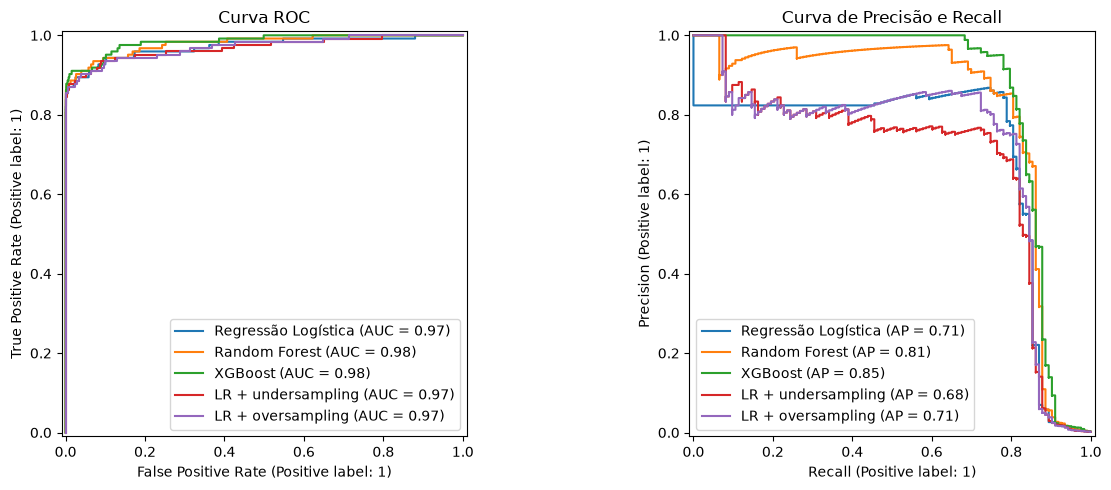

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for nome, p in probas.items():
    RocCurveDisplay.from_predictions(y_test, p, name=nome, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test, p, name=nome, ax=axes[1])
axes[0].set_title("Curva ROC"); axes[1].set_title("Curva de Precisão e Recall")
plt.tight_layout(); plt.show()

### Ajuste do limiar de decisão (XGBoost)

Em vez de usar 0,5, escolho o limiar que maximiza o F1 na curva de precisão e recall,
mantendo o recall da fraude como prioridade.

In [10]:
p_xgb = probas["XGBoost"]
prec, rec, lim = precision_recall_curve(y_test, p_xgb)
f1s = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
melhor = lim[np.argmax(f1s)]
print(f"limiar escolhido: {melhor:.3f}")

comp = pd.DataFrame({"limiar 0.5": metricas(y_test, p_xgb, 0.5),
                     f"limiar {melhor:.3f}": metricas(y_test, p_xgb, melhor)}).T
display(comp)

pred = (p_xgb >= melhor).astype(int)
print(classification_report(y_test, pred, target_names=["normal", "fraude"], digits=4))
pd.DataFrame(confusion_matrix(y_test, pred), index=["real normal", "real fraude"],
             columns=["prev. normal", "prev. fraude"])

limiar escolhido: 0.953


,precisão,recall,F1,ROC AUC,AUPRC
limiar 0.5,0.8534,0.8049,0.8285,0.9841,0.8533
limiar 0.953,0.9505,0.7805,0.8571,0.9841,0.8533


              precision    recall  f1-score   support

      normal     0.9996    0.9999    0.9998     71079
      fraude     0.9505    0.7805    0.8571       123

    accuracy                         0.9996     71202
   macro avg     0.9751    0.8902    0.9285     71202
weighted avg     0.9995    0.9996    0.9995     71202



,prev. normal,prev. fraude
real normal,71074,5
real fraude,27,96


## 5. Explicar

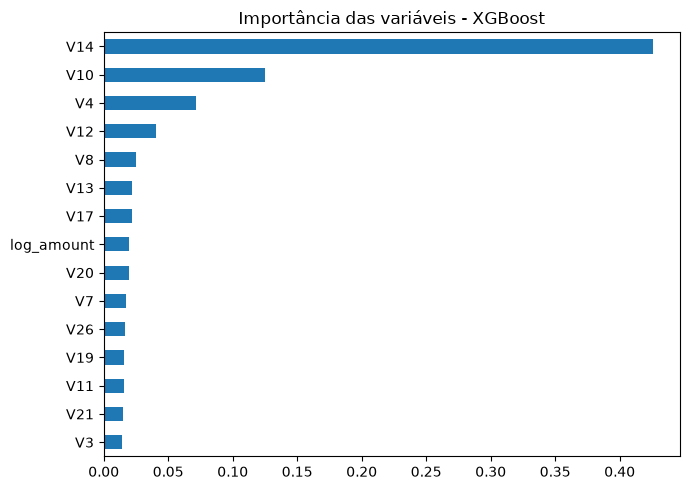

In [11]:
xgb = modelos["XGBoost"]
imp = pd.Series(xgb.feature_importances_, index=X.columns).sort_values(ascending=False).head(15)
imp[::-1].plot.barh(figsize=(7, 5), title="Importância das variáveis - XGBoost")
plt.tight_layout(); plt.show()

Top 8 variáveis por |SHAP| médio:
V14   1.8769
V4    1.7271
V12   1.0285
V10   0.8426
V11   0.6098
V3    0.5447
V8    0.4246
V19   0.3858


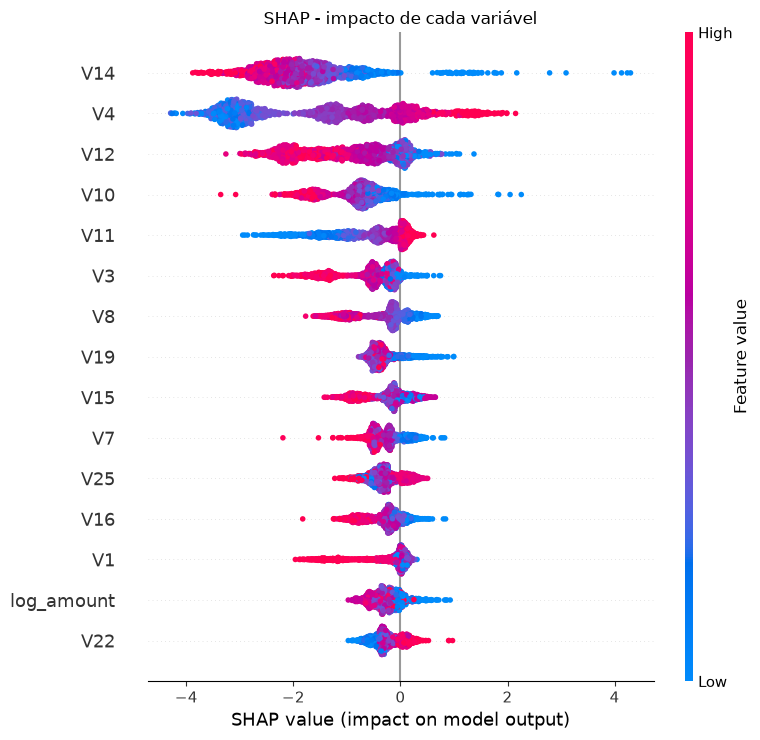

In [12]:
amostra = X_test_s.sample(2000, random_state=RANDOM_STATE)
explainer = shap.TreeExplainer(xgb)
valores = explainer.shap_values(amostra)
ranking = pd.Series(np.abs(valores).mean(axis=0), index=amostra.columns).sort_values(ascending=False)
print("Top 8 variáveis por |SHAP| médio:")
print(ranking.head(8).round(4).to_string())
shap.summary_plot(valores, amostra, max_display=15, show=False)
plt.title("SHAP - impacto de cada variável"); plt.tight_layout(); plt.show()

probabilidade de fraude: 0.9992305040359497


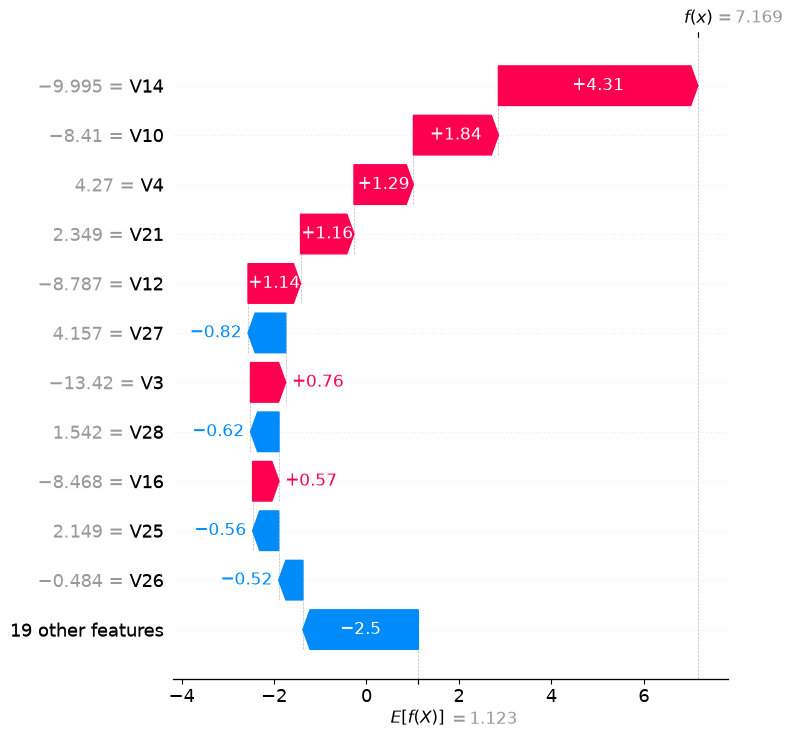

In [13]:
# Explicação de uma fraude específica detectada pelo modelo
fraudes_detectadas = X_test_s[(y_test == 1) & (p_xgb >= melhor)]
caso = fraudes_detectadas.iloc[[0]]
exp = explainer(caso)
print("probabilidade de fraude:", float(xgb.predict_proba(caso)[0, 1]))
shap.plots.waterfall(exp[0], max_display=12, show=False)
plt.tight_layout(); plt.show()

## Conclusões

- A acurácia não serve para esse problema; recall, precisão, F1 e AUPRC mostram o desempenho real.
- O XGBoost teve o melhor equilíbrio entre recall e precisão; a regressão logística pega muitas fraudes, mas com muitos alarmes falsos.
- Ajustar o limiar mudou bastante o resultado: com 0,5 o modelo é mais agressivo; com o limiar escolhido pelo F1, os falsos positivos caem muito.
- O SHAP mostra quais variáveis concentram as decisões (ranking impresso acima) e, no gráfico de cascata, quanto cada uma empurrou uma fraude específica para a classe positiva.